<a href="https://colab.research.google.com/github/samiah-ss/Binary-Image-Classifier/blob/main/Samiah_Siddiqua_What_Factors_are_Most_Correlated_to_Heart_Disease%3F_Big_Data_at_Berkeley_Bootcamp_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **What Factors are Most Correlated to Heart Disease?**
## A Project by Samiah Siddiqua
---
### Aiming to discover which factors are most linked to the development of heart disease, this project was presented at University of California, Berkeley, for the Fall 2026 Big Data at Berkeley Bootcamp.

## **Background**

According to the U.S. Centers of Disease Control and Prevention, heart disease is the leading cause of death for men and women worldwide—to put that into perspective, it kills at least one person every 34 seconds.

These statistics make advances in prevention necessary. However, with over 300 factors linked to cardiovascular disease, it is hard to pinpoint what to prevent in the first place. Thus, I decided to research and explore these factors to answer the question, "What Factors are Most Correlated to Heart Disease?"

Answering this question is important in terms of preventing of cardiovascular disease and the deaths it could cause going forward.

In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub

## **The Dataset**
[*Indicators of Heart Disease*](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease), as updated in 2022, contains survey data of over 400,000 Americans in relation to their health and the factors that may or may not lead them to heart disease.

---

This dataset features rows of patient responses that detail approximately 40 factors, such as whether or not a respondent had depressive disorder.

In [55]:
path = kagglehub.dataset_download("kamilpytlak/personal-key-indicators-of-heart-disease")
data_path = f"{path}/2022/heart_2022_with_nans.csv"
df = pd.read_csv(data_path)
df.head(1)
df.sample(n=5)

Using Colab cache for faster access to the 'personal-key-indicators-of-heart-disease' dataset.


,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
24780,Arkansas,Female,Good,0.0,0.0,NaN,Yes,8.0,NaN,No,No,No,No,No,No,No,No,Yes,No,No,Yes,Yes,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 75 to 79,1.68,90.72,32.28,No,NaN,Yes,Yes,"Yes, received tetanus shot but not sure what type",No,NaN
358620,Texas,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,8.0,1 to 5,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 50 to 54,NaN,NaN,NaN,Yes,Yes,No,Yes,"Yes, received Tdap",No,No
304241,Oklahoma,Male,Good,0.0,0.0,NaN,No,6.0,"6 or more, but not all",Yes,No,Yes,No,No,No,No,NaN,Yes,No,No,No,No,No,No,No,Former smoker,Never used e-cigarettes in my entire life,Yes,"White only, Non-Hispanic",Age 75 to 79,1.73,81.65,27.37,No,No,NaN,Yes,"Yes, received tetanus shot, but not Tdap",No,No
222826,Montana,Male,Very good,8.0,10.0,Within past 2 years (1 year but less than 2 ye...,Yes,7.0,None of them,No,No,No,No,No,No,Yes,No,No,No,No,No,No,No,No,No,Never smoked,Never used e-cigarettes in my entire life,No,"White only, Non-Hispanic",Age 18 to 24,1.83,81.65,24.41,Yes,Yes,Yes,No,"Yes, received Tdap",Yes,Yes
329117,South Carolina,Female,Excellent,2.0,30.0,Within past 2 years (1 year but less than 2 ye...,Yes,5.0,1 to 5,No,No,No,No,No,No,Yes,No,No,No,No,No,Yes,No,No,Yes,Current smoker - now smokes every day,Use them some days,Yes,Hispanic,Age 25 to 29,1.68,81.65,29.05,No,Yes,No,NaN,NaN,Yes,No


## **Data Cleaning**
My code will perform cleaning steps such as renaming and unhiding missing columns, dropping unnecessary columns, checking and removing missing or NaN values—since this version of the dataset has NaN values unremoved—and deleting identical columns. Since patient responses are strings by default, I will have them changed to numerical data types using booleans and create binary columns.

It is important to clean this dataset for my project specifically, because I can only use floats and integers to calculate correlation between different factors and heart disease.

In [73]:
df.rename(columns = {'HadHeartAttack' : 'HadHeartDisease'}, inplace = True)
pd.set_option('display.max_columns', None)

my_factors = ['HadHeartDisease', 'HadAngina', 'HadStroke', 'HadDepressiveDisorder', 'DifficultyWalking', 'SmokerStatus', 'AlcoholDrinkers', 'AgeCategory']
heart_disease_df = df[my_factors].copy()

binary_columns = ['HadHeartDisease', 'HadAngina', 'HadStroke', 'HadDepressiveDisorder', 'DifficultyWalking', 'AlcoholDrinkers']

heart_disease_df.isnull().sum()
heart_disease_df.dropna()
heart_disease_df.drop_duplicates()

heart_disease_df.head()
heart_disease_df[df['HadHeartDisease'] == 'Yes'].head()

,HadHeartDisease,HadAngina,HadStroke,HadDepressiveDisorder,DifficultyWalking,SmokerStatus,AlcoholDrinkers,AgeCategory
5,Yes,No,Yes,No,No,Never smoked,No,Age 80 or older
26,Yes,Yes,No,No,No,Current smoker - now smokes some days,Yes,Age 65 to 69
31,Yes,Yes,Yes,Yes,Yes,Never smoked,Yes,Age 75 to 79
32,Yes,Yes,No,Yes,Yes,Former smoker,No,Age 60 to 64
34,Yes,Yes,No,Yes,Yes,Never smoked,No,Age 80 or older


In [57]:
for col in binary_columns:
  heart_disease_df[col] = heart_disease_df[col].map({'Yes' : 1, 'No': 0})

heart_disease_df['SmokerStatus']

heart_disease_df['SmokerStatus'] = heart_disease_df['SmokerStatus'].map({
    'Current smoker - now smokes every day': 1,
    'Current smoker - now smokes some days': 1,
    'Former smoker': 0,
    'Never smoked' : 0
})

heart_disease_df['AgeCategory'] = heart_disease_df['AgeCategory'].map({
    'Age 18 to 24' : 21,
    'Age 25 to 29': 27,
    'Age 30 to 34': 32,
    'Age 35 to 39': 37,
    'Age 40 to 44': 42,
    'Age 45 to 49': 47,
    'Age 50 to 54': 52,
    'Age 55 to 59': 57,
    'Age 60 to 64': 62,
    'Age 65 to 69': 67,
    'Age 70 to 74': 72,
    'Age 75 to 79': 77,
})

## **Finding Correlation**

I have created and concatenated two balanced dataframes—one with a random sample of patients who have heart disease, one with an equal sample of patients who do not—such that this new dataframe has an even amount of people with the disease and people without it. I can then calculate and read a correlation matrix to determine which factors are most likely to cause heart disease.

In [58]:
sick = heart_disease_df[heart_disease_df['HadHeartDisease'] == 1]
healthy = heart_disease_df[heart_disease_df['HadHeartDisease'] == 0]

healthy_sample = healthy.sample(n = len(sick), random_state = 42)

balanced_df = pd.concat([sick, healthy_sample])

balanced_df = balanced_df.sample(frac = 1, random_state = 42).reset_index(drop = True)

In [65]:
corr_matrix = balanced_df.corr()

corr_matrix

,HadHeartDisease,HadAngina,HadStroke,HadDepressiveDisorder,DifficultyWalking,SmokerStatus,AlcoholDrinkers,AgeCategory
HadHeartDisease,1.000000,0.529169,0.260774,0.059680,0.296047,0.087036,-0.162421,0.402869
HadAngina,0.529169,1.000000,0.187245,0.051459,0.222984,0.026355,-0.102162,0.305420
HadStroke,0.260774,0.187245,1.000000,0.086632,0.210205,0.056813,-0.100772,0.148156
HadDepressiveDisorder,0.059680,0.051459,0.086632,1.000000,0.191407,0.140661,-0.045656,-0.074914
DifficultyWalking,0.296047,0.222984,0.210205,0.191407,1.000000,0.110861,-0.197871,0.233254
SmokerStatus,0.087036,0.026355,0.056813,0.140661,0.110861,1.000000,-0.009446,-0.025080
AlcoholDrinkers,-0.162421,-0.102162,-0.100772,-0.045656,-0.197871,-0.009446,1.000000,-0.134929
AgeCategory,0.402869,0.305420,0.148156,-0.074914,0.233254,-0.025080,-0.134929,1.000000


## **Exploratory Data Analysis**
These three visualizations support an answer to my question.

---

First, a my correlation heatmap shows how certain factors can be correlated to one another and to heart disease. Redder boxes signal stronger correlation in comparison to bluer ones. In terms of my project, the heatmap quickly reveals how angina has the strongest correlation to heart disease out of all other factors. Additionally, age category and difficulty walking also have moderate correlation.

---

Second, a bar plot visualizes one of the strongest uncovered correlations—that of angina's relation to heart disease. It proves that the likelihood of having heart disease increases for patients with angina compared to patients without it.

---

Finally, a line plot displays how as age increases, so does the risk of heart disease—meaning that these two factors may exhibit a direct relationship.

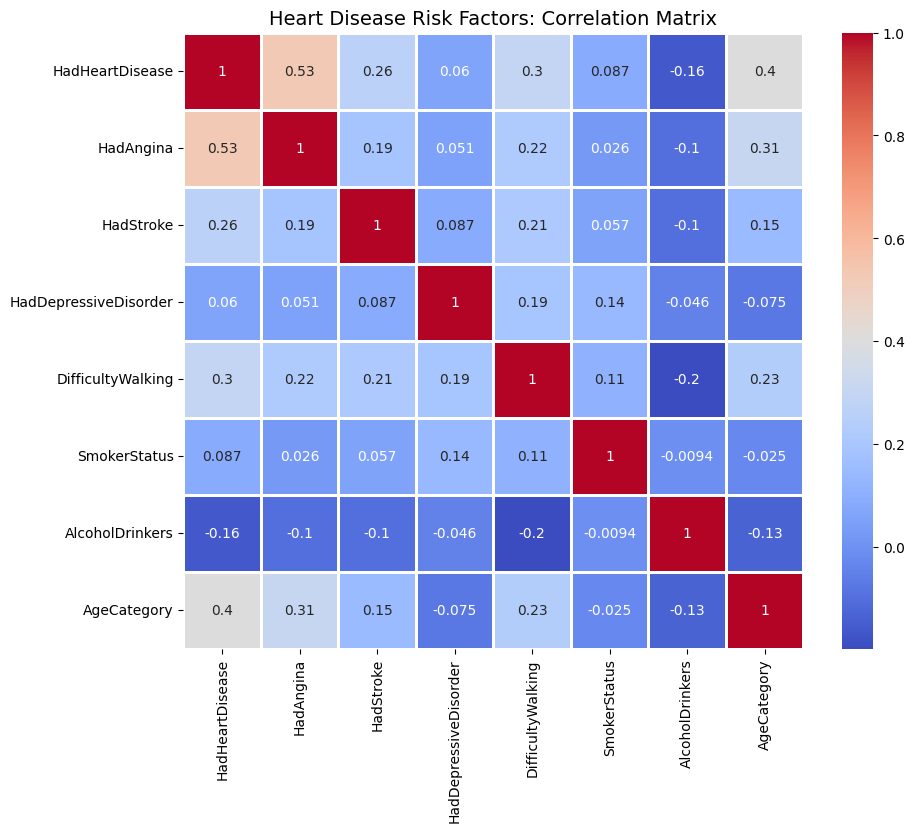

In [67]:
plt.figure(figsize = (10, 8))
sns.heatmap(balanced_df.corr(), annot = True, cmap = 'coolwarm', linewidths = 1)
plt.title("Heart Disease Risk Factors: Correlation Matrix", fontsize = 14)
plt.show()

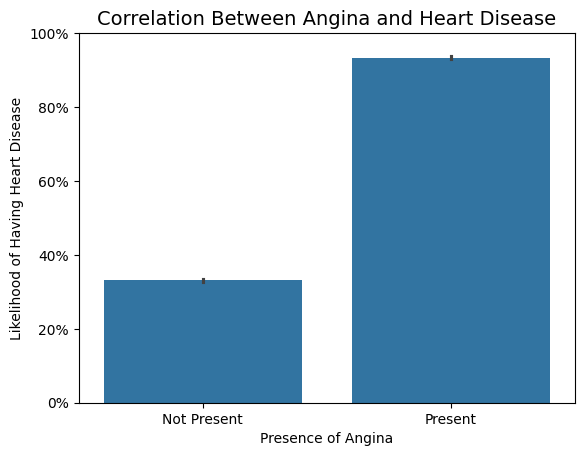

In [70]:
sns.barplot(data = balanced_df, x = 'HadAngina', y = 'HadHeartDisease')

plt.title("Correlation Between Angina and Heart Disease", fontsize = 14)
plt.xticks([0, 1,], ["Not Present", "Present"])
plt.yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0%", "20%", "40%", "60%", "80%", "100%"])
plt.xlabel("Presence of Angina")
plt.ylabel("Likelihood of Having Heart Disease")

plt.show()

Text(0, 0.5, 'Likelihood of Having Heart Disease')

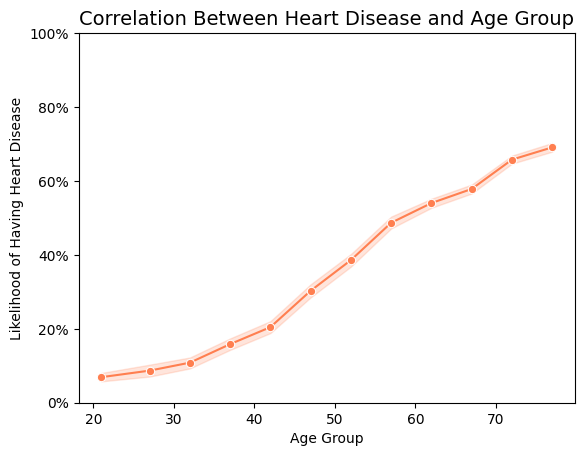

In [71]:
sns.lineplot(data = balanced_df, x = "AgeCategory", y = "HadHeartDisease", marker = "o", color = "#FF7F50")

plt.title("Correlation Between Heart Disease and Age Group", fontsize = 14)
plt.yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0%", "20%", "40%", "60%", "80%", "100%"])
plt.xlabel("Age Group")
plt.ylabel("Likelihood of Having Heart Disease")

## **Conclusion**
Although the null hypothesis would be that there is no factor correlated to heart disease, a permutation test rejects it and validates the alternative hypothesis of there being, in fact, correlations from certain factors to heart disease. Through this project, I have discovered that angina, age group, and difficulty walking are prominent among other factors in terms of their correlation to cardiovascular disease.

In [72]:
observed_corr = heart_disease_df["HadHeartDisease"].corr(heart_disease_df["HadAngina"])
print("Observed Correlation:", observed_corr)

corrs = []

for i in range(1000):
	shuffled = np.random.permutation(heart_disease_df["HadAngina"])
	new_corr = heart_disease_df["HadHeartDisease"].corr(pd.Series(shuffled))
	corrs.append(new_corr)

p_value = np.mean(np.abs(corrs) >= abs(observed_corr))
print("P-value:", p_value)

if p_value > 0.05:
  print("Conclusion: Null Hypothesis Accepted!")
else:
  print("Conclusion: Alternative Hypothesis Accpeted, Null Hypothesis Rejected!")

Observed Correlation: 0.44495022391214595
P-value: 0.0
Conclusion: Alternative Hypothesis Accpeted, Null Hypothesis Rejected!


Made by Samiah Siddiqua

[View my presentation!](https://canva.link/shcmck21e91qyei)

[Link to this project's Github repository](https://github.com/samiah-ss)